# Fintech vs Banks: What Are US Consumers Complaining About?

### An analysis of 976,529 complaints to the Consumer Financial Protection Bureau, 2020–2026

In this notebook we explore the [CFPB Consumer Complaint Database](https://www.consumerfinance.gov/data-research/consumer-complaints/), a public US government record of complaints about financial products and the companies behind them. We use every complaint received from January 2020 to mid-November 2026 about four product families where fintechs and banks compete directly: **checking and savings accounts, credit cards, prepaid cards, and money transfers (including crypto)**.

Imagine we're working with a fintech's customer experience lead. They want to know how complaints against digital-first providers compare with traditional banks: which problems drive them, how that has changed, and how well companies resolve them.

We'll try to answer the following questions:

- How has complaint volume changed since 2020?
- What drove the sharp rise in money-transfer complaints in 2025?
- Which companies receive the most complaints?
- Do fintech customers complain about different things than bank customers, for the same product?
- How common are fraud and scam complaints, and for whom?
- How do companies respond, and does that differ between fintechs and banks once we account for the type of problem?

> **Key findings**
>
> - **Complaints about these four products quadrupled**, from 66,427 in 2020 to 265,328 in 2025, with 203,506 in 2026 up to mid-November. Fintechs' share was 12–17% from 2021 to 2024, jumped to 28% in 2025 because of a one-off spike, and is still 24% in 2026 without one.
> - **Most of the 2025 money-transfer rise came in eight days.** Cash App and Zelle received 41,752 money-transfer complaints on 14–21 January 2025, equal to 62% of that year's rise. Most were labelled "Other transaction problem". Cash App's jump began on 16 January, the day the CFPB announced an order against its parent, Block. Zelle's began two days earlier, so that order can't explain it, and the data doesn't show what did.
> - **Fintech and bank customers complain about different things, even for the same product.** In checking and savings, fintech customers complain nearly twice as often about unexpected charges and debits (19.2% vs 10.5%); bank customers complain more about low-balance problems such as overdrafts (8.6% vs 2.4%). In money transfers, fraud is a bigger share of bank complaints: 56% vs 42% for fintechs outside January 2025, and 51% vs 24% if a catch-all label that mixes fraud with other transaction problems isn't counted as fraud.
> - **Fintechs close far fewer complaints with monetary relief than banks** for accounts (5.9% vs 15.7%), credit cards (5.3% vs 19.1%) and prepaid cards (3.1% vs 30.1%), after adjusting for the mix of issues. These gaps hold without Block (Cash App), without January 2025 and, for prepaid cards, without American Express. In money transfers, the gap comes from Cash App: it closed none of its 56,459 money-transfer complaints with monetary relief, and without it fintechs give relief more often than banks (12.7% vs 9.6%).
> - **Outcomes vary widely within each group.** In money transfers, 27.9% of Coinbase's complaints and 13.6% of PayPal's close with monetary relief (raw rates), against 0% for Cash App and Zelle; in checking, Bank of America's rate is 35.4% and Capital One's 3.6%.

## Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
pd.set_option('display.max_colwidth', 80)

FULL_DATA = Path('data/processed/complaints_2020plus.parquet')   # built by scripts/ (not committed)
SAMPLE_DATA = Path('data/sample/complaints_sample.csv')           # 20,000-row random sample (committed)
FIG_DIR = Path('figures')
FIG_DIR.mkdir(exist_ok=True)


def save(fig, name):
    """Save a figure to figures/ so it can be used in the README."""
    fig.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')


GROUP_ORDER = ['Bank / credit union', 'Fintech', 'Zelle (bank-owned network)',
               'Money transmitter', 'Credit bureau', 'Other']
GROUP_COLORS = {'Bank / credit union': '#4c72b0', 'Fintech': '#dd8452',
                'Zelle (bank-owned network)': '#8172b3', 'Money transmitter': '#937860',
                'Credit bureau': '#8c8c8c', 'Other': '#cccccc'}

## 1. Loading and preparing the data

The full dataset (976,529 complaints) is downloaded from the CFPB's public API by the scripts in `scripts/` and saved as a Parquet file. If that file isn't there, the notebook falls back to a 20,000-row random sample, so anyone can run it without downloading the data first; the counts will then be much smaller.

In [2]:
if FULL_DATA.exists():
    df = pd.read_parquet(FULL_DATA)
    USING_SAMPLE = False
else:
    df = pd.read_csv(SAMPLE_DATA, parse_dates=['Date received', 'Date sent to company'])
    USING_SAMPLE = True
    print('Full data not found: running on the 20,000-row sample. Counts will be much smaller.\n')

print(f'{len(df):,} complaints, {df.shape[1]} columns')
df.info()

976,529 complaints, 15 columns
<class 'pandas.DataFrame'>
RangeIndex: 976529 entries, 0 to 976528
Data columns (total 15 columns):
 #   Column                        Non-Null Count   Dtype         
---  ------                        --------------   -----         
 0   Date received                 976529 non-null  datetime64[us]
 1   Product                       976529 non-null  str           
 2   Sub-product                   976464 non-null  str           
 3   Issue                         976524 non-null  str           
 4   Sub-issue                     786667 non-null  str           
 5   Company public response       397272 non-null  str           
 6   Company                       976529 non-null  str           
 7   State                         959127 non-null  str           
 8   ZIP code                      974886 non-null  str           
 9   Tags                          151789 non-null  str           
 10  Submitted via                 976529 non-null  str          

A few things to fix before we start:

- **Dates.** The API gives timestamps in UTC. The CFPB is a US agency, so we convert them to US Eastern time before taking the date. Otherwise a complaint sent on the evening of 31 December would count in the next year.
- **Products.** In 2023 the CFPB split "Credit card or prepaid card" into "Credit card" and "Prepaid card". To keep trends continuous, we assign the older complaints to credit or prepaid using their sub-product.
- **Complete months only.** The data ends mid-month, so monthly trends stop at the last complete month.

In [3]:
def to_eastern_date(s):
    s = pd.to_datetime(s)
    if s.dt.tz is None:
        s = s.dt.tz_localize('UTC')
    return s.dt.tz_convert('America/New_York').dt.tz_localize(None).dt.normalize()


df['date'] = to_eastern_date(df['Date received'])
df['sent_date'] = to_eastern_date(df['Date sent to company'])
df['month'] = df['date'].dt.to_period('M')
df['year'] = df['date'].dt.year

PREPAID_SUBS = {'General-purpose prepaid card', 'Government benefit card', 'Gift card',
                'Payroll card', 'Student prepaid card'}
family = df['Product'].map({'Checking or savings account': 'Checking or savings',
                            'Credit card': 'Credit card',
                            'Prepaid card': 'Prepaid card',
                            'Money transfer, virtual currency, or money service': 'Money transfer & crypto'})
old_cards = df['Product'].eq('Credit card or prepaid card')
family[old_cards] = np.where(df.loc[old_cards, 'Sub-product'].isin(PREPAID_SUBS), 'Prepaid card', 'Credit card')
df['product_family'] = family

# Converting to US Eastern time moves a handful of 1 January 2020 (UTC) complaints into 2019; keep 2020 onwards
before = len(df)
df = df[df['date'] >= '2020-01-01'].copy()
print(f'Dropped {before - len(df):,} complaints dated 31 Dec 2019 in US Eastern time')
FAMILY_ORDER = ['Checking or savings', 'Credit card', 'Prepaid card', 'Money transfer & crypto']

last_date = df['date'].max()
LAST_FULL_MONTH = (last_date + pd.Timedelta(days=1)).to_period('M') - 1
print(f'Complaints from {df["date"].min():%d %b %Y} to {last_date:%d %b %Y} (US Eastern dates)')
print(f'Last complete month: {LAST_FULL_MONTH}')
print(f'Product family missing for {df["product_family"].isna().sum():,} rows')
pd.crosstab(df['Product'], df['product_family'])

Dropped 11 complaints dated 31 Dec 2019 in US Eastern time
Complaints from 01 Jan 2020 to 16 Nov 2026 (US Eastern dates)
Last complete month: 2026-10
Product family missing for 0 rows


product_family,Checking or savings,Credit card,Money transfer & crypto,Prepaid card
Product,,,,
Checking or savings account,357294,0,0,0
Credit card,0,272955,0,0
Credit card or prepaid card,0,125305,0,15580
"Money transfer, virtual currency, or money service",0,0,184855,0
Prepaid card,0,0,0,20529


Are the timestamps really UTC? If they are, complaints filed during the US working day should appear about an hour earlier in UTC in summer, when US clocks go forward, and very few should be filed at 2–5am US Eastern time.

In [4]:
utc = pd.to_datetime(df['Date received'])
if utc.dt.tz is not None:
    utc = utc.dt.tz_convert('UTC').dt.tz_localize(None)
hour = utc.dt.hour + utc.dt.minute / 60
daytime = hour.between(10, 24, inclusive='left')
winter = utc.dt.month.isin([12, 1, 2])
summer = utc.dt.month.isin([6, 7, 8])
print(f'Average UTC time of daytime complaints: winter {hour[daytime & winter].mean():.2f}h, '
      f'summer {hour[daytime & summer].mean():.2f}h')
print(f'Filed 07:00–09:59 UTC (2–5am US Eastern): {utc.dt.hour.between(7, 9).mean():.1%}')
print(f'Filed 00:00–04:59 UTC (US evening, so dated one day earlier in Eastern time): {(utc.dt.hour < 5).mean():.1%}')

Average UTC time of daytime complaints: winter 18.27h, summer 17.92h
Filed 07:00–09:59 UTC (2–5am US Eastern): 4.0%
Filed 00:00–04:59 UTC (US evening, so dated one day earlier in Eastern time): 16.4%


### Grouping companies

The core of this analysis is a judgement call: which companies count as **fintechs** and which as **banks**. We use simple, transparent rules, applied in this order (the first match wins):

1. **Credit bureau**: Equifax, TransUnion, Experian. Their complaints in these products are almost all about credit reports, so we leave them out of the fintech-vs-bank comparison.
2. **Zelle (bank-owned network)**: Early Warning Services runs Zelle and is owned by large banks, so it fits neither group cleanly.
3. **Money transmitter**: long-established transfer companies such as Western Union and MoneyGram.
4. **Fintech**: digital-first payment, banking, lending and crypto companies (Cash App's parent Block, PayPal and Venmo, Chime, Coinbase, SoFi and others). SoFi and Green Dot now hold bank charters, but we keep them as fintechs because that's how they're known to customers.
5. **Bank / credit union**: banks, card issuers and credit unions.
6. **Other**: everything else, mainly payment processors, debt collectors and smaller non-bank lenders.

The full mapping for every company with many complaints is printed below, so readers can check it.

In [5]:
GROUP_RULES = [
    ('Credit bureau', r'EQUIFAX|TRANSUNION|EXPERIAN'),
    ('Zelle (bank-owned network)', r'EARLY WARNING'),
    ('Money transmitter', r'WESTERN UNION|MONEYGRAM|RIA ENVIA|SIGUE|INTERMEX|EURONET|DOLEX|VIAMERICAS'),
    ('Fintech', r'BLOCK, INC|PAYPAL|CHIME|COINBASE|SOFI |SOFI$|SOFI TECH|SOCIAL FINANCE|ROBINHOOD|FINCO SERVICES'
                r'|CREDIT KARMA|TRANSFERWISE|WISE PAYMENTS|AFFIRM|AVANT HOLDING|SELF FINANCIAL|WINKLEVOSS|FORIS DAX'
                r'|NETSPEND|KLARNA|UPGRADE, INC|REMITLY|KRAKEN|REVOLUT|BILT TECHNOLOGIES|BRANCH MESSENGER'
                r'|ALBERT CORPORATION|DAVE OPERATING|IMPRINT PAYMENTS|SKRILL|KIKOFF|RELAY FINANCIAL|BLOCKFI'
                r'|BLOCKCHAIN\.COM|DAILYPAY|NOVO PLATFORM|B9, INC|MAJORITY USA|BAM MANAGEMENT|VARO|MONEYLION'
                r'|STASH|ACORNS|ASPIRATION|BANKMOBILE TECHNOLOGIES|GREEN DOT'),
    ('Bank / credit union', r'BANK|BANCORP|BANCSHARES|BANC-CORP|BANCO|CREDIT UNION|JPMORGAN|CAPITAL ONE'
                            r'|WELLS FARGO|CITIBANK|SYNCHRONY|AMERICAN EXPRESS|UNITED SERVICES AUTOMOBILE'
                            r'|BREAD FINANCIAL|TRUIST|CITIZENS FINANCIAL|COMERICA|FIFTH THIRD|ALLY FINANCIAL'
                            r'|HUNTINGTON|REGIONS FINANCIAL|KEYCORP|HSBC|SANTANDER|BBVA|AXOS|FIRST HORIZON'
                            r'|WEBSTER|CULLEN/FROST|ARVEST|FULTON FINANCIAL|UMB FINANCIAL|BOK FINANCIAL'
                            r'|PINNACLE FINANCIAL|M&T|NAVY FEDERAL|PENTAGON FEDERAL|MUFG|SOUTHSTATE|OLD NATIONAL'
                            r'|FIRST MERCHANTS|SUNTRUST|ATLANTIC UNION|SIMMONS FIRST|AMERIS|VALLEY NATIONAL'
                            r'|ASSOCIATED BANC|CADENCE|EAST WEST|DISCOVER|GOLDMAN SACHS'),
]

company = df['Company'].str.upper()
conditions = [company.str.contains(pattern, regex=True, na=False) for _, pattern in GROUP_RULES]
df['group'] = np.select(conditions, [g for g, _ in GROUP_RULES], default='Other')

coverage = df['group'].value_counts().reindex(GROUP_ORDER).fillna(0).astype(int).to_frame('complaints')
coverage['% of all'] = (coverage['complaints'] / len(df) * 100).round(1)
coverage

,complaints,% of all
group,,
Bank / credit union,655981,67.2
Fintech,185404,19.0
Zelle (bank-owned network),24580,2.5
Money transmitter,4355,0.4
Credit bureau,59786,6.1
Other,46412,4.8


In [6]:
MIN_LIST = 1000 if not USING_SAMPLE else 20
mapping = (df.groupby(['group', 'Company']).size().rename('complaints').reset_index()
           .query('complaints >= @MIN_LIST')
           .assign(group=lambda d: pd.Categorical(d['group'], GROUP_ORDER, ordered=True))
           .sort_values(['group', 'complaints'], ascending=[True, False]))
print(f'Companies with at least {MIN_LIST:,} complaints, by group:')
print(mapping.to_string(index=False))

Companies with at least 1,000 complaints, by group:
                     group                                             Company  complaints
       Bank / credit union                                JPMORGAN CHASE & CO.       81549
       Bank / credit union               BANK OF AMERICA, NATIONAL ASSOCIATION       73217
       Bank / credit union                   CAPITAL ONE FINANCIAL CORPORATION       70595
       Bank / credit union                               WELLS FARGO & COMPANY       64037
       Bank / credit union                                      CITIBANK, N.A.       63710
       Bank / credit union                                 SYNCHRONY FINANCIAL       33699
       Bank / credit union                            AMERICAN EXPRESS COMPANY       30291
       Bank / credit union                           NAVY FEDERAL CREDIT UNION       26281
       Bank / credit union                                        U.S. BANCORP       22086
       Bank / credit union            

To keep names readable in charts, we use short names for the best-known companies.

In [7]:
SHORT_NAMES = {
    'JPMORGAN CHASE & CO.': 'JPMorgan Chase', 'BANK OF AMERICA, NATIONAL ASSOCIATION': 'Bank of America',
    'Block, Inc.': 'Block (Cash App)', 'CAPITAL ONE FINANCIAL CORPORATION': 'Capital One',
    'WELLS FARGO & COMPANY': 'Wells Fargo', 'CITIBANK, N.A.': 'Citibank', 'Paypal Holdings, Inc': 'PayPal',
    'SYNCHRONY FINANCIAL': 'Synchrony', 'AMERICAN EXPRESS COMPANY': 'American Express',
    'Chime Financial Inc': 'Chime', 'NAVY FEDERAL CREDIT UNION': 'Navy Federal CU',
    'Early Warning Services, LLC': 'Early Warning (Zelle)', 'U.S. BANCORP': 'U.S. Bank',
    'EQUIFAX, INC.': 'Equifax', 'TRANSUNION INTERMEDIATE HOLDINGS, INC.': 'TransUnion',
    'Experian Information Solutions Inc.': 'Experian', 'Bread Financial Holdings, Inc.': 'Bread Financial',
    'TD BANK US HOLDING COMPANY': 'TD Bank', 'DISCOVER BANK': 'Discover', 'GOLDMAN SACHS BANK USA': 'Goldman Sachs',
    'PNC Bank N.A.': 'PNC', 'TRUIST FINANCIAL CORPORATION': 'Truist', 'BARCLAYS BANK DELAWARE': 'Barclays',
    'UNITED SERVICES AUTOMOBILE ASSOCIATION': 'USAA', 'Coinbase, Inc.': 'Coinbase',
    'SOFI TECHNOLOGIES, INC.': 'SoFi', 'ROBINHOOD MARKETS INC.': 'Robinhood',
}
fallback = (df['Company'].str.title().str.replace(r',? (Inc|Llc|N\.A|Corporation|Company|Holdings|Corp)\.?$', '', regex=True)
            .str.slice(0, 32))
df['company_short'] = df['Company'].map(SHORT_NAMES).fillna(fallback)

## 2. How has complaint volume changed since 2020?

Let's start with monthly complaint counts for each product family, up to the last complete month.

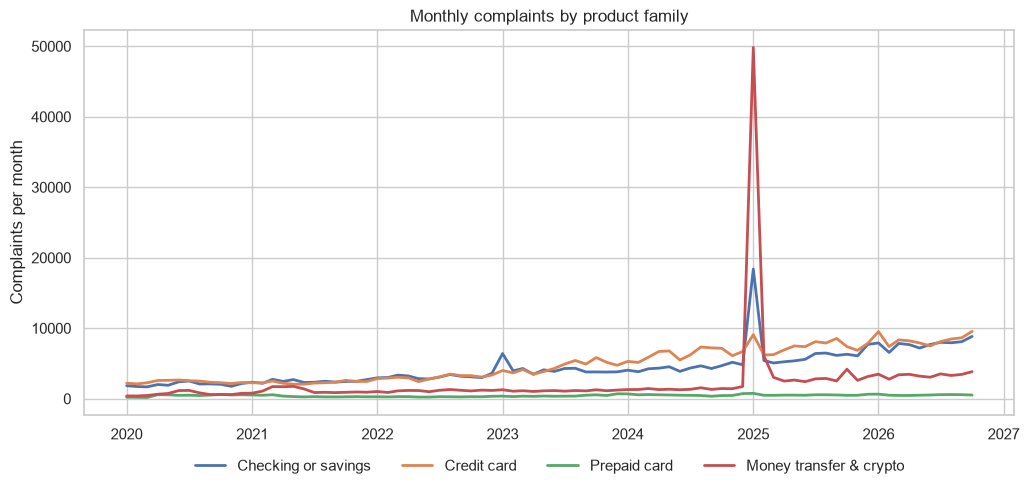

In [8]:
monthly = (df[df['month'] <= LAST_FULL_MONTH]
           .groupby(['month', 'product_family']).size().unstack(fill_value=0)
           .reindex(columns=FAMILY_ORDER))

fig, ax = plt.subplots(figsize=(12, 5))
for fam in FAMILY_ORDER:
    ax.plot(monthly.index.to_timestamp(), monthly[fam], label=fam, linewidth=2)
ax.set(title='Monthly complaints by product family', xlabel='', ylabel='Complaints per month')
ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.08), frameon=False)
save(fig, 'monthly_complaints_by_product')
plt.show()

In [9]:
yearly = pd.crosstab(df['product_family'], df['year']).reindex(FAMILY_ORDER)
yearly.loc['Total'] = yearly.sum()
print(f'Note: {last_date.year} covers complaints up to {last_date:%d %b %Y} only.')
yearly

Note: 2026 covers complaints up to 16 Nov 2026 only.


year,2020,2021,2022,2023,2024,2025,2026
product_family,,,,,,,
Checking or savings,24242,29560,37577,49877,52834,84205,78999
Credit card,28524,27666,36582,54416,75997,89998,85077
Prepaid card,5355,4159,3299,5033,6322,6500,5441
Money transfer & crypto,8306,13895,13538,13745,16757,84625,33989
Total,66427,75280,90996,123071,151910,265328,203506


Complaints about these four product families quadrupled, from 66,427 in 2020 to 151,910 in 2024 and 265,328 in 2025. Credit card and checking complaints rose steadily, each roughly tripling between 2020 and 2025 (credit cards 28,524 → 89,998; checking 24,242 → 84,205). Money-transfer complaints stayed between about 8,000 and 17,000 a year until 2024, then jumped to 84,625 in 2025. Much of that jump came in January (section 3), and checking complaints spiked that month too. In 2026, up to 16 November, there are 203,506 complaints, with checking and credit cards already close to their 2025 totals.

Some of this growth may reflect more people using the CFPB's complaint process rather than more problems; the data can't separate the two.

## 3. What drove the 2025 rise in money-transfer complaints?

Money-transfer complaints jumped in 2025. Let's see which companies drove it, when, and what the complaints were about. The data can show **what** changed; it can't tell us **why**, so we describe the pattern rather than claim a cause.

In [10]:
mt = df[df['product_family'].eq('Money transfer & crypto')]
top_2025 = mt.loc[mt['year'].eq(2025), 'company_short'].value_counts().head(5).index.tolist()

by_year = (pd.crosstab(mt['company_short'], mt['year'])
           .reindex(top_2025))
by_year.loc['All other companies'] = pd.crosstab(mt['company_short'], mt['year']).drop(index=top_2025).sum()
by_year.loc['Total'] = by_year.sum()
print(f'Money-transfer complaints by year ({last_date.year} is partial):')
by_year

Money-transfer complaints by year (2026 is partial):


year,2020,2021,2022,2023,2024,2025,2026
company_short,,,,,,,
Block (Cash App),1033,865,1085,1596,1926,42573,8896
Early Warning (Zelle),167,283,693,449,483,19703,557
PayPal,1899,4706,2596,2813,3069,5486,8990
JPMorgan Chase,416,845,1232,1273,1392,1967,1548
Chime,30,101,179,363,510,1741,1485
All other companies,4761,7095,7753,7251,9377,13155,12513
Total,8306,13895,13538,13745,16757,84625,33989


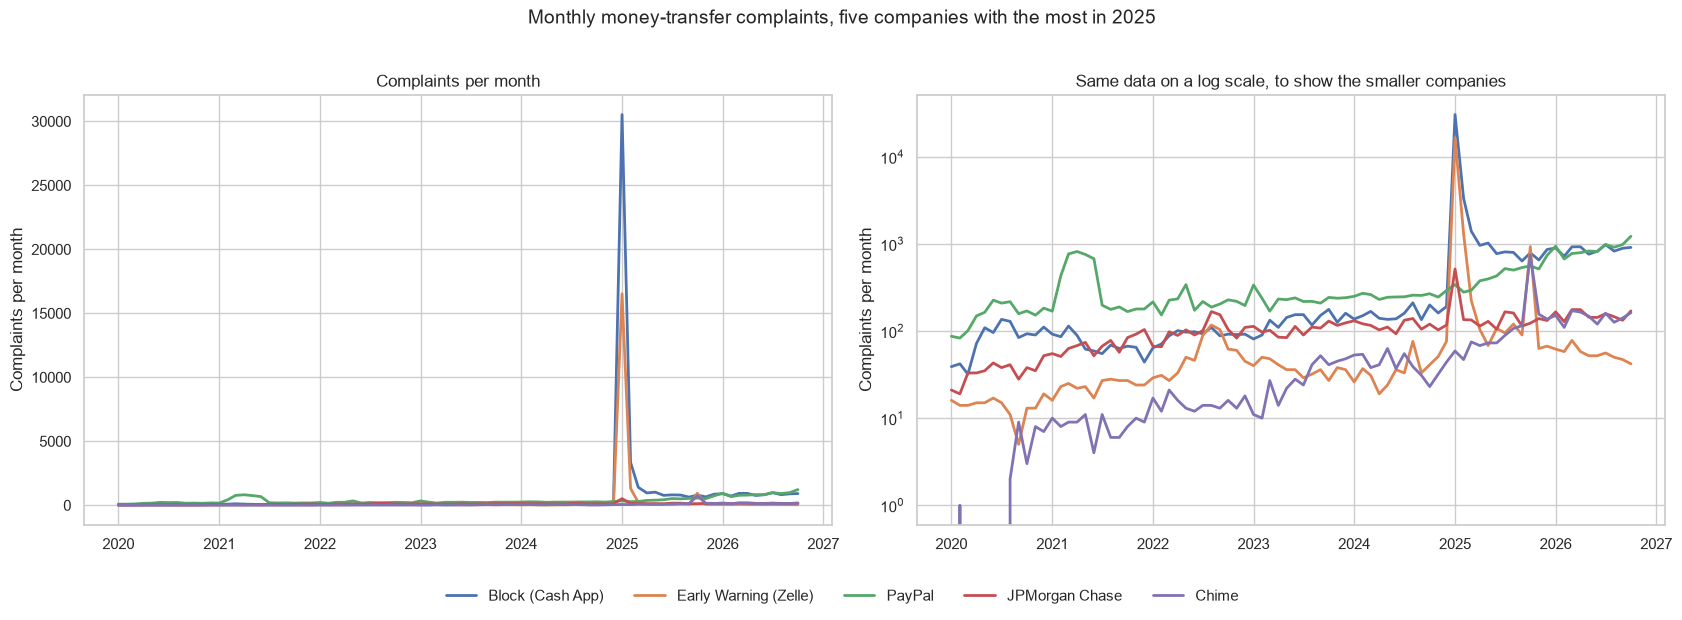

Peak month for each company:
                      peak month  complaints that month
company_short                                          
Block (Cash App)         2025-01                  30531
Early Warning (Zelle)    2025-01                  16528
PayPal                   2026-10                   1223
JPMorgan Chase           2025-01                    515
Chime                    2025-10                    742


In [11]:
mt_monthly = (mt[(mt['month'] <= LAST_FULL_MONTH) & mt['company_short'].isin(top_2025)]
              .groupby(['month', 'company_short']).size().unstack(fill_value=0)
              .reindex(columns=top_2025, fill_value=0))

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
for ax, scale in zip(axes, ['linear', 'log']):
    for name in top_2025:
        ax.plot(mt_monthly.index.to_timestamp(), mt_monthly[name], label=name, linewidth=2)
    ax.set_yscale(scale)
    ax.set(xlabel='', ylabel='Complaints per month')
axes[0].set_title('Complaints per month')
axes[1].set_title('Same data on a log scale, to show the smaller companies')
fig.suptitle('Monthly money-transfer complaints, five companies with the most in 2025', fontsize=14, y=1.02)
fig.tight_layout()
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.01), frameon=False)
save(fig, 'money_transfer_spike')
plt.show()

peak = mt_monthly.idxmax()
print('Peak month for each company:')
print(pd.DataFrame({'peak month': peak.astype(str), 'complaints that month': mt_monthly.max()}).to_string())

What were those complaints about? For the two companies behind most of the rise, let's compare the share of each problem (sub-issue, or issue where no sub-issue is given) in 2024 and 2025.

In [12]:
mt = mt.assign(problem=mt['Sub-issue'].fillna(mt['Issue']))
spike_names = top_2025[:2]
tables = {}
for name in spike_names:
    c = mt[mt['company_short'].eq(name) & mt['year'].isin([2024, 2025])]
    share = pd.crosstab(c['problem'], c['year'], normalize='columns') * 100
    counts = pd.crosstab(c['problem'], c['year'])
    top = share.sort_values(2025, ascending=False).head(6) if 2025 in share else share.head(6)
    tables[name] = top.round(1).join(counts.add_prefix('n_'), how='left')
pd.concat(tables)

year                                                                            2024  2025  n_2024  n_2025
                      problem                                                                             
Block (Cash App)      Other transaction problem                                  8.3  76.5     160   32562
                      Fraud or scam                                             31.3   7.2     602    3053
                      Unauthorized transactions or other transaction problem    25.3   6.6     488    2804
                      Trouble accessing funds in your mobile or digital wallet  13.2   2.6     254    1114
                      Other service problem                                      2.3   2.4      44    1019
                      Managing, opening, or closing your mobile wallet account   8.8   1.9     170     818
Early Warning (Zelle) Other transaction problem                                 10.8  83.3      52   16407
                      Fraud or scam                                             59.2   6.4     286    1254
                      Confusing or missing disclosures                           1.9   4.1       9     815
                      Unauthorized transactions or other transaction problem    10.8   2.3      52     461
                      Other service problem                                      4.1   1.7      20     343
                      Money was not available when promised                      3.9   0.5      19      89

Was the January 2025 jump spread across the month, or concentrated in a few days? Many complaints on a few days point to a shared trigger, rather than many unrelated problems.

In [13]:
jan = mt[mt['company_short'].isin(spike_names) & mt['month'].eq(pd.Period('2025-01', 'M'))]
daily = jan.groupby(['date', 'company_short']).size().unstack(fill_value=0)
daily['total'] = daily.sum(axis=1)
print('Busiest days in January 2025:')
print(daily.sort_values('total', ascending=False).head(8).to_string(), '\n')
for name in spike_names:
    c = jan[jan['company_short'].eq(name)]
    top3 = c['date'].value_counts().head(3)
    print(f"{name}: {len(c):,} complaints in January 2025; {top3.sum() / len(c):.0%} on its 3 busiest days "
          f"({', '.join(d.strftime('%d %b') for d in top3.index)})")

Busiest days in January 2025:
company_short  Block (Cash App)  Early Warning (Zelle)  total
date                                                         
2025-01-17                10194                   2240  12434
2025-01-16                 5447                   2524   7971
2025-01-18                 4948                   2903   7851
2025-01-20                 3425                    755   4180
2025-01-15                   14                   2838   2852
2025-01-19                 1632                    804   2436
2025-01-14                   10                   2354   2364
2025-01-21                 1088                    576   1664 

Block (Cash App): 30,531 complaints in January 2025; 67% on its 3 busiest days (17 Jan, 16 Jan, 18 Jan)
Early Warning (Zelle): 16,528 complaints in January 2025; 50% on its 3 busiest days (18 Jan, 15 Jan, 16 Jan)


How much of the year's rise came in that short window, and when did each company's jump start? We look at the eight days from 14 to 21 January, and at each company's daily counts around them.

In [14]:
per_year = mt['year'].value_counts()
rise = per_year.get(2025, 0) - per_year.get(2024, 0)
window = mt[mt['date'].between('2025-01-14', '2025-01-21')]
in_window = window['company_short'].isin(spike_names).sum()
print(f'Money-transfer complaints: {per_year.get(2024, 0):,} in 2024 and {per_year.get(2025, 0):,} in 2025, a rise of {rise:,}.')
print(f'{" and ".join(spike_names)} received {in_window:,} complaints on 14–21 January 2025'
      + (f', equal to {in_window / rise:.0%} of the rise.' if rise > 0 else '.'), '\n')

days = pd.date_range('2025-01-10', '2025-01-21')
around = (jan[jan['date'].isin(days)].groupby(['date', 'company_short']).size().unstack(fill_value=0)
          .reindex(index=days, columns=spike_names, fill_value=0))
around.index = around.index.strftime('%a %d %b')
print('Daily money-transfer complaints, 10–21 January 2025:')
print(around.to_string(), '\n')

cur = last_date.year
n_months_cur = LAST_FULL_MONTH.month if LAST_FULL_MONTH.year == cur else 0
rows = {}
for name in spike_names:
    c = mt[mt['company_short'].eq(name)]
    rows[name] = {'2024': c['year'].eq(2024).sum() / 12,
                  '2025 excl. January': (c['year'].eq(2025) & c['month'].ne(pd.Period('2025-01', 'M'))).sum() / 11,
                  f'{cur} (complete months)': ((c['year'].eq(cur) & (c['month'] <= LAST_FULL_MONTH)).sum()
                                               / n_months_cur if n_months_cur else np.nan)}
print('Average money-transfer complaints per month:')
pd.DataFrame(rows).T.round(0)

Money-transfer complaints: 16,757 in 2024 and 84,625 in 2025, a rise of 67,868.
Block (Cash App) and Early Warning (Zelle) received 41,752 complaints on 14–21 January 2025, equal to 62% of the rise. 

Daily money-transfer complaints, 10–21 January 2025:
company_short  Block (Cash App)  Early Warning (Zelle)
Fri 10 Jan                    8                      4
Sat 11 Jan                    4                      1
Sun 12 Jan                    5                      0
Mon 13 Jan                    7                      2
Tue 14 Jan                   10                   2354
Wed 15 Jan                   14                   2838
Thu 16 Jan                 5447                   2524
Fri 17 Jan                10194                   2240
Sat 18 Jan                 4948                   2903
Sun 19 Jan                 1632                    804
Mon 20 Jan                 3425                    755
Tue 21 Jan                 1088                    576 

Average money-transfer compla

,2024,2025 excl. January,2026 (complete months)
Block (Cash App),160.0,1095.0,867.0
Early Warning (Zelle),40.0,289.0,56.0


**Context from outside the data.** On 16 January 2025 the CFPB [ordered Block to pay up to $120 million in redress and a $55 million penalty](https://www.consumerfinance.gov/enforcement/actions/block-inc/) over Cash App's handling of fraud and customer service. Cash App's complaints jumped that same day. Zelle's jump started earlier, on 14 January, two days before the Block order, and doesn't line up with the CFPB's own case against Early Warning Services (Zelle) and three of its owner banks, which was [filed in December 2024 and dropped on 4 March 2025](https://www.crowdfundinsider.com/2025/03/237009-cfpb-drops-zelle-fraud-lawsuit-against-major-us-banking-institutions/). So the timing points to the Block order as a possible trigger for Cash App only, and the data doesn't show what set off Zelle's spike. Either way, the timing is a possible link, not a proven cause.

Two companies drove the 2025 jump. Cash App (Block) went from 1,926 money-transfer complaints in 2024 to 42,573 in 2025, and Zelle (Early Warning Services) from 483 to 19,703. Both peaked in January 2025 (30,531 and 16,528 complaints). The eight days of 14–21 January alone brought 41,752 complaints for the two companies, equal to 62% of the 67,868 rise in money-transfer complaints between 2024 and 2025.

The two spikes didn't start together. Zelle went from 2 complaints on 13 January to 2,354 on 14 January and 2,838 on 15 January. Cash App stayed below 15 a day until 16 January, when it received 5,447, followed by 10,194 the next day. Cash App's jump matches the day the CFPB announced its order against Block, but Zelle's started two days before it and doesn't match the dates of the CFPB's case against Zelle either. So the data suggests separate triggers, and doesn't show what they were.

What people complained about changed too. "Other transaction problem" made up 76.5% of Cash App's 2025 money-transfer complaints, against 8.3% in 2024, and 83.3% of Zelle's, against 10.8%. In 2024, fraud, scams and unauthorised transactions had been the main complaints for both.

Afterwards, Zelle returned to its old level (56 complaints a month in 2026, against 40 in 2024). Cash App didn't: it averaged 867 a month in 2026's complete months, more than five times its 2024 level of 160. PayPal rose steadily: its money-transfer complaints went from 5,486 in 2025 to 8,990 in 2026 so far, and October 2026, the last complete month, was its highest month so far (1,223). The log-scale panel shows both trends.

## 4. Which companies receive the most complaints?

An important caveat first: **complaint counts are not adjusted for size.** The CFPB doesn't publish how many customers each company has, so a large bank will get more complaints than a small one simply because it serves more people. These counts show where complaints come from, not which company is "worst".

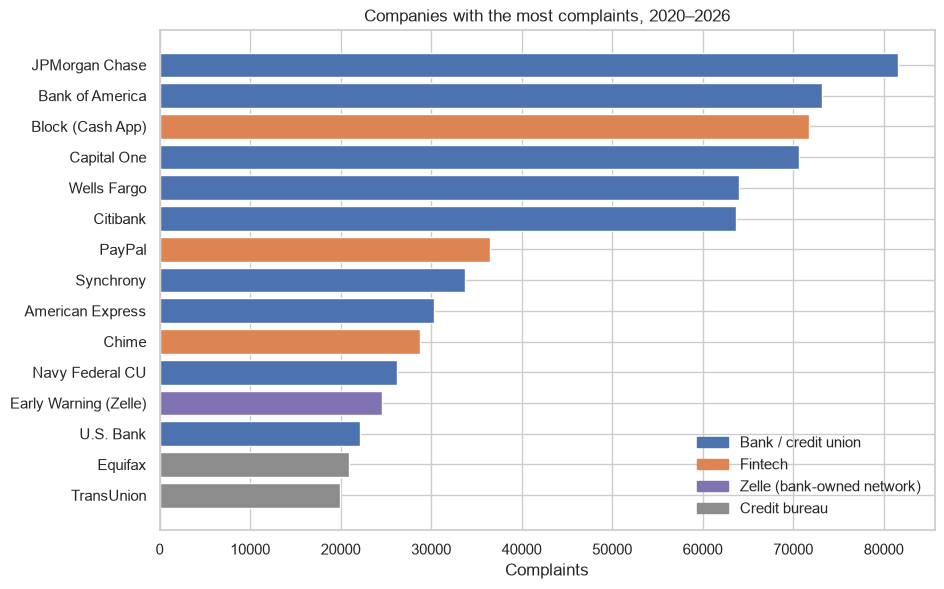

,company_short,group,complaints,% of all
Company,,,,
JPMORGAN CHASE & CO.,JPMorgan Chase,Bank / credit union,81549,8.4
"BANK OF AMERICA, NATIONAL ASSOCIATION",Bank of America,Bank / credit union,73217,7.5
"Block, Inc.",Block (Cash App),Fintech,71782,7.4
CAPITAL ONE FINANCIAL CORPORATION,Capital One,Bank / credit union,70595,7.2
WELLS FARGO & COMPANY,Wells Fargo,Bank / credit union,64037,6.6
"CITIBANK, N.A.",Citibank,Bank / credit union,63710,6.5
"Paypal Holdings, Inc",PayPal,Fintech,36480,3.7
SYNCHRONY FINANCIAL,Synchrony,Bank / credit union,33699,3.5
AMERICAN EXPRESS COMPANY,American Express,Bank / credit union,30291,3.1


In [15]:
top15 = df['Company'].value_counts().head(15)
top15_df = (top15.rename('complaints').to_frame()
            .join(df.drop_duplicates('Company').set_index('Company')[['group', 'company_short']]))
top15_df['% of all'] = (top15_df['complaints'] / len(df) * 100).round(1)

fig, ax = plt.subplots(figsize=(10, 6.5))
plot = top15_df.iloc[::-1]
ax.barh(plot['company_short'], plot['complaints'], color=plot['group'].map(GROUP_COLORS))
ax.legend(handles=[Patch(color=GROUP_COLORS[g], label=g) for g in GROUP_ORDER if g in set(plot['group'])],
          frameon=False, loc='lower right')
ax.set(title='Companies with the most complaints, 2020–2026', xlabel='Complaints', ylabel='')
save(fig, 'top_companies')
plt.show()

top15_df[['company_short', 'group', 'complaints', '% of all']]

In [16]:
group_year = pd.crosstab(df['group'], df['year']).reindex(GROUP_ORDER)
group_year_share = (group_year / group_year.sum() * 100).round(1)
print(f'Share of complaints by group and year (%; {last_date.year} is partial):')
group_year_share

Share of complaints by group and year (%; 2026 is partial):


year,2020,2021,2022,2023,2024,2025,2026
group,,,,,,,
Bank / credit union,85.8,77.8,80.1,75.1,66.5,51.6,67.4
Fintech,8.3,16.6,12.7,11.6,12.4,28.1,23.7
Zelle (bank-owned network),0.3,0.5,0.9,0.6,0.5,7.7,0.6
Money transmitter,0.8,0.7,0.6,0.4,0.5,0.3,0.4
Credit bureau,0.3,0.5,0.9,7.8,14.6,8.2,2.3
Other,4.4,4.0,4.8,4.6,5.4,4.0,5.6


Complaints are concentrated in a few large companies: the five biggest banks (JPMorgan Chase, Bank of America, Capital One, Wells Fargo and Citibank) account for 36% of all complaints. Cash App is third overall (71,782 complaints, 7.4%), but 42,573 of those are money-transfer complaints from 2025, many from one week in January, so its ranking partly reflects that spike. PayPal (3.7%) and Chime (2.9%) are the other fintechs in the top 15.

Fintechs' share of complaints was 8.3% in 2020 and 12–17% from 2021 to 2024. It jumped to 28.1% in 2025 because of the Cash App spike, but it's still 23.7% in 2026, when there was no spike. Part of the 2026 rise reflects fewer credit bureau complaints in these products (2.3%, down from 14.6% in 2024), which raises everyone else's share. Credit bureaus are left out of the comparisons because their complaints here are mostly about credit reports. Without customer numbers, none of this says which company treats its customers worse.

## 5. Do fintech and bank customers complain about different things?

To compare like with like, we compare the **mix of problems within the same product**. Otherwise fintechs would look different simply because they sell different products. We use the two product families where both groups have plenty of complaints: checking/savings accounts and money transfers. Credit bureaus are left out, and Zelle is shown on its own.

In [17]:
COMPARE = ['Bank / credit union', 'Fintech', 'Zelle (bank-owned network)']
cmp = df[df['group'].isin(COMPARE)]

print('Complaints per product family and group:')
pd.crosstab(cmp['product_family'], cmp['group']).reindex(index=FAMILY_ORDER, columns=COMPARE)

Complaints per product family and group:


group,Bank / credit union,Fintech,Zelle (bank-owned network)
product_family,,,
Checking or savings,292516,51566,2212
Credit card,303848,16046,28
Prepaid card,19527,7221,5
Money transfer & crypto,40090,110571,22335


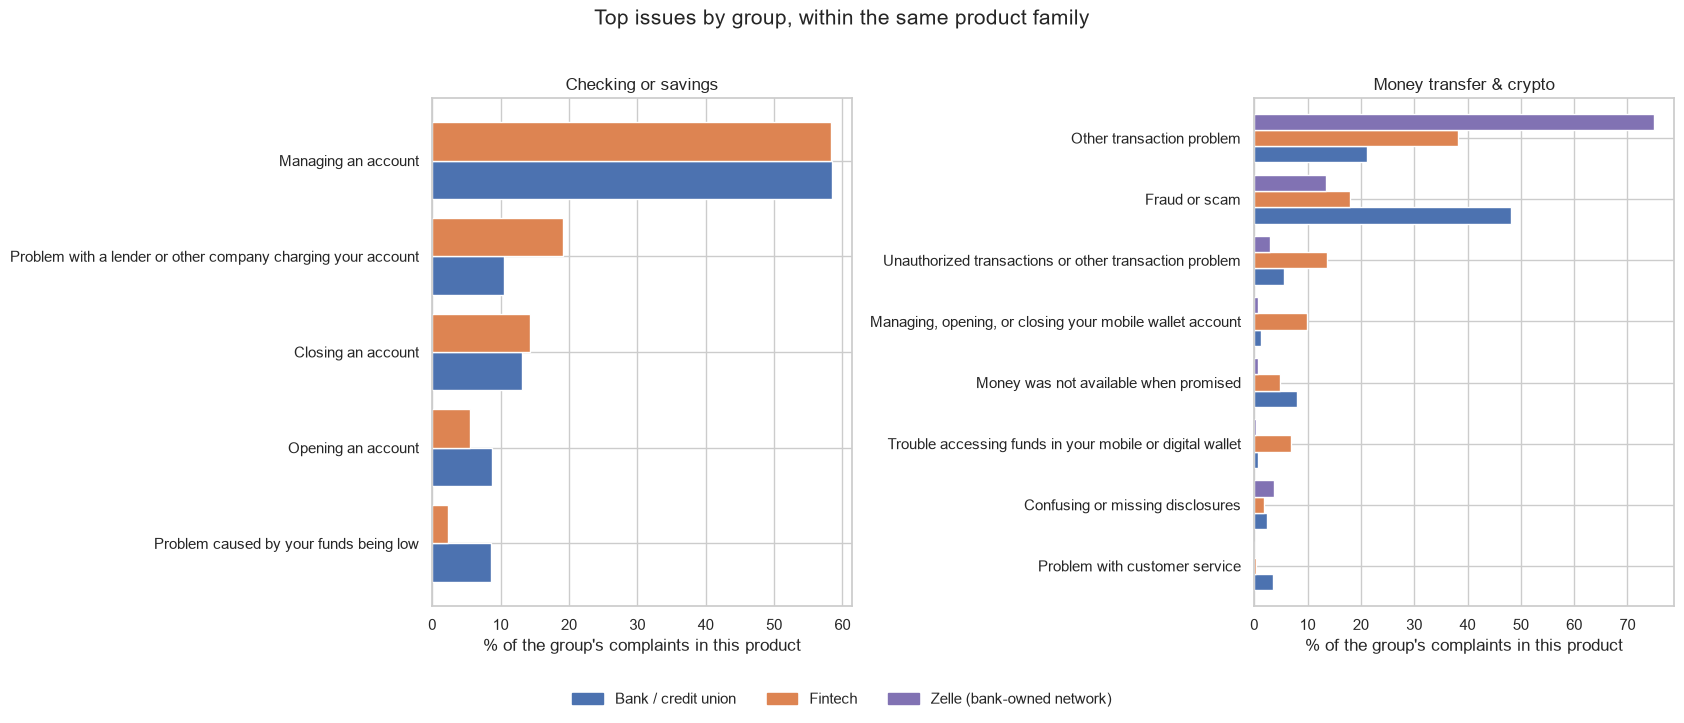

group                                                                                 Bank / credit union  Fintech  Zelle (bank-owned network)
                        Issue                                                                                                                 
Checking or savings     Managing an account                                                          58.5     58.3                         NaN
                        Problem with a lender or other company charging your account                 10.5     19.2                         NaN
                        Closing an account                                                           13.2     14.3                         NaN
                        Opening an account                                                            8.7      5.5                         NaN
                        Problem caused by your funds being low                                        8.6      2.4                         NaN
Money transfer & crypto Other transaction problem                                                    21.1     38.2                        75.0
                        Fraud or scam                                                                48.1     17.9                        13.4
                        Unauthorized transactions or other transaction problem                        5.6     13.6                         3.0
                        Managing, opening, or closing your mobile wallet account                      1.3     10.0                         0.7
                        Money was not available when promised                                         8.1      4.9                         0.7
                        Trouble accessing funds in your mobile or digital wallet                      0.7      7.0                         0.4
                        Confusing or missing disclosures                                              2.5      1.9                         3.8
                        Problem with customer service                                                 3.5      0.4                         0.0

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
issue_tables = {}
for ax, fam in zip(axes, ['Checking or savings', 'Money transfer & crypto']):
    sub = cmp[cmp['product_family'].eq(fam)]
    groups = [g for g in COMPARE if (sub['group'] == g).sum() >= max(30, 0.01 * len(sub))]
    share = (pd.crosstab(sub['Issue'], sub['group'], normalize='columns') * 100)[groups]
    share = share[share.max(axis=1) >= 1]                      # drop issues under 1% for every group
    share = share.loc[share.max(axis=1).sort_values(ascending=False).index[:8]]
    issue_tables[fam] = share.round(1)
    share.iloc[::-1].plot(kind='barh', ax=ax, width=0.8, color=[GROUP_COLORS[g] for g in groups])
    ax.set(title=fam, xlabel='% of the group\'s complaints in this product', ylabel='')
    ax.get_legend().remove()
fig.suptitle('Top issues by group, within the same product family', fontsize=15, y=1.02)
fig.tight_layout()
fig.legend(handles=[Patch(color=GROUP_COLORS[g], label=g) for g in COMPARE], ncol=3, loc='upper center',
           bbox_to_anchor=(0.5, -0.01), frameon=False)
save(fig, 'issues_by_group')
plt.show()

pd.concat(issue_tables)

The January 2025 spike added tens of thousands of "Other transaction problem" complaints for Cash App and Zelle, which could distort these shares. As a check, here is the same comparison with complaints received in January 2025 left out.

In [19]:
JAN_2025 = pd.Period('2025-01', 'M')
no_jan = cmp[cmp['month'].ne(JAN_2025)]
check = {}
for fam, share_full in issue_tables.items():
    sub = no_jan[no_jan['product_family'].eq(fam)]
    share_nj = (pd.crosstab(sub['Issue'], sub['group'], normalize='columns') * 100).reindex(
        index=share_full.index, columns=share_full.columns)
    check[fam] = pd.concat({'all months': share_full, 'excl. Jan 2025': share_nj.round(1)}, axis=1)
pd.concat(check)

all months              excl. Jan 2025          \
group                                                                                Bank / credit union Fintech Bank / credit union Fintech   
                        Issue                                                                                                                  
Checking or savings     Managing an account                                                         58.5    58.3                59.4    58.3   
                        Problem with a lender or other company charging your account                10.5    19.2                10.9    19.2   
                        Closing an account                                                          13.2    14.3                13.7    14.3   
                        Opening an account                                                           8.7     5.5                 9.0     5.5   
                        Problem caused by your funds being low                                       8.6     2.4                 6.4     2.3   
Money transfer & crypto Other transaction problem                                                   21.1    38.2                20.8    18.2   
                        Fraud or scam                                                               48.1    17.9                48.8    23.7   
                        Unauthorized transactions or other transaction problem                       5.6    13.6                 5.4    18.1   
                        Managing, opening, or closing your mobile wallet account                     1.3    10.0                 1.4    13.7   
                        Money was not available when promised                                        8.1     4.9                 8.2     6.6   
                        Trouble accessing funds in your mobile or digital wallet                     0.7     7.0                 0.7     9.4   
                        Confusing or missing disclosures                                             2.5     1.9                 2.0     2.4   
                        Problem with customer service                                                3.5     0.4                 3.6     0.5   

                                                                                                     all months             excl. Jan 2025  
group                                                                                Zelle (bank-owned network) Zelle (bank-owned network)  
                        Issue                                                                                                               
Checking or savings     Managing an account                                                                 NaN                        NaN  
                        Problem with a lender or other company charging your account                        NaN                        NaN  
                        Closing an account                                                                  NaN                        NaN  
                        Opening an account                                                                  NaN                        NaN  
                        Problem caused by your funds being low                                              NaN                        NaN  
Money transfer & crypto Other transaction problem                                                          75.0                       44.5  
                        Fraud or scam                                                                      13.4                       38.6  
                        Unauthorized transactions or other transaction problem                              3.0                        5.9  
                        Managing, opening, or closing your mobile wallet account                            0.7                        2.4  
                        Money was not available when promised                                    

For checking and savings accounts, most complaints in both groups are about managing an account (about 58%). The differences are in the rest: fintech customers complain nearly twice as often about charges or debits they didn't expect ("Problem with a lender or other company charging your account", 19.2% vs 10.5%), while bank customers complain more about low-balance problems such as overdraft and insufficient-funds fees (8.6% vs 2.4%), possibly reflecting different fee models. Leaving out January 2025 barely changes these shares.

For money transfers, the January 2025 spike distorts the fintech figures, so the version without it is the fair comparison. Without January 2025, 23.7% of fintech complaints are "Fraud or scam", against 48.8% for banks. Fintech customers' complaints are spread more widely: "Other transaction problem" (18.2%), unauthorised or other transaction problems (18.1%), managing their mobile wallet account (13.7%) and getting access to their funds (9.4%). With January 2025 included, "Other transaction problem" jumps to 38.2% of fintech complaints and 75.0% of Zelle's.

## 6. How common are fraud and scam complaints, and for whom?

Fraud is a recurring theme for payment apps. We flag a complaint as **fraud-related** if its issue or sub-issue mentions fraud, scams, unauthorised transactions, stolen money, identity theft or an account opened without consent. The CFPB reworded some labels in 2023 (for example, "Account opened as a result of fraud" became "Account opened without my consent or knowledge"), so the pattern covers both versions. We look at checking/savings and money transfers, where these problems are most common.

Most common fraud-related labels:
Sub-issue
Fraud or scam                                             42103
Transaction was not authorized                            33460
Unauthorized transactions or other transaction problem    18008
Account opened without my consent or knowledge             5782
Account opened as a result of fraud                        5536
Lost or stolen money order                                  510
Lost or stolen check                                        287
Problem with fraud alerts or security freezes               189 



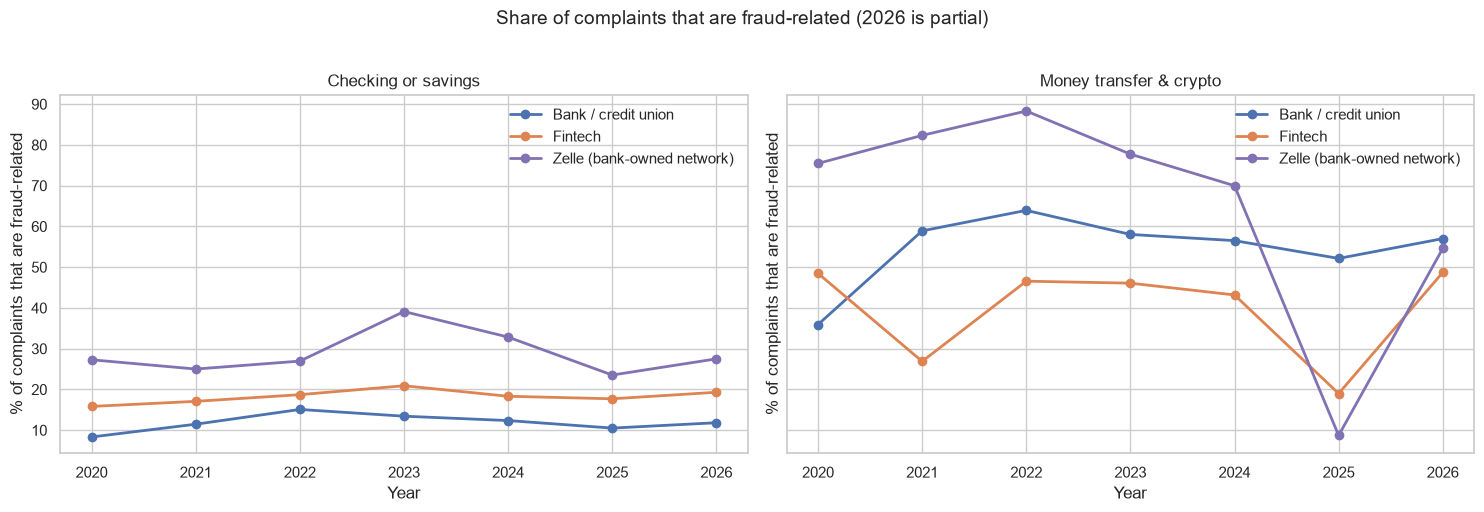

year                                                2020  2021  2022  2023  2024  2025  2026
product_family          group                                                               
Checking or savings     Bank / credit union          8.3  11.5  15.1  13.4  12.4  10.5  11.8
                        Fintech                     15.8  17.1  18.7  20.9  18.3  17.7  19.3
                        Zelle (bank-owned network)  27.3  25.0  27.0  39.1  32.8  23.5  27.5
Money transfer & crypto Bank / credit union         35.9  58.9  63.9  58.0  56.5  52.1  57.0
                        Fintech                     48.5  26.9  46.6  46.1  43.2  19.0  48.7
                        Zelle (bank-owned network)  75.4  82.3  88.3  77.7  70.0   8.7  54.6

In [20]:
FRAUD_PATTERN = r'fraud|scam|unauthori[sz]ed|not authori[sz]ed|stolen|identity theft|without my consent'
cmp_fr = cmp[cmp['product_family'].isin(['Checking or savings', 'Money transfer & crypto'])].copy()
cmp_fr['fraud'] = (cmp_fr['Issue'].str.contains(FRAUD_PATTERN, case=False, na=False)
                   | cmp_fr['Sub-issue'].str.contains(FRAUD_PATTERN, case=False, na=False))

print('Most common fraud-related labels:')
print(cmp_fr.loc[cmp_fr['fraud'], 'Sub-issue'].fillna(cmp_fr['Issue']).value_counts().head(8).to_string(), '\n')

fraud_rate = (cmp_fr.groupby(['product_family', 'group', 'year'])['fraud'].agg(['mean', 'size'])
              .reset_index())
fraud_rate['% fraud-related'] = fraud_rate['mean'] * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, fam in zip(axes, ['Checking or savings', 'Money transfer & crypto']):
    for g in COMPARE:
        r = fraud_rate[(fraud_rate['product_family'] == fam) & (fraud_rate['group'] == g) & (fraud_rate['size'] >= 30)]
        if len(r):
            ax.plot(r['year'], r['% fraud-related'], marker='o', linewidth=2, label=g, color=GROUP_COLORS[g])
    ax.set(title=fam, xlabel='Year', ylabel='% of complaints that are fraud-related')
    ax.legend(frameon=False)
fig.suptitle(f'Share of complaints that are fraud-related ({last_date.year} is partial)', fontsize=14, y=1.02)
fig.tight_layout()
save(fig, 'fraud_share')
plt.show()

(fraud_rate.pivot_table(index=['product_family', 'group'], columns='year', values='% fraud-related')
 .round(1))

Two checks on these numbers:

- **A catch-all label.** "Unauthorized transactions or other transaction problem" mixes fraud with other transaction problems, so the strict version below doesn't count it as fraud on its own.
- **The January 2025 spike.** One share per group for the whole period, with and without January 2025, is the fairest single comparison.

In [21]:
CATCH_ALL = 'Unauthorized transactions or other transaction problem'


def flags_fraud(labels):
    return labels.str.replace(CATCH_ALL, '', regex=False).str.contains(FRAUD_PATTERN, case=False, na=False)


cmp_fr['fraud_strict'] = flags_fraud(cmp_fr['Issue']) | flags_fraud(cmp_fr['Sub-issue'])
print(f'Complaints flagged only because of the catch-all label: {(cmp_fr["fraud"] & ~cmp_fr["fraud_strict"]).sum():,}\n')

strict = (cmp_fr.groupby(['product_family', 'group', 'year'])['fraud_strict'].mean() * 100).unstack().round(1)
print('% fraud-related, strict version (catch-all label not counted):')
print(strict.to_string(), '\n')

nj = cmp_fr[cmp_fr['month'].ne(JAN_2025)]
keys = ['product_family', 'group']
pd.DataFrame({
    '% fraud, all months': cmp_fr.groupby(keys)['fraud'].mean() * 100,
    '% fraud, excl. Jan 2025': nj.groupby(keys)['fraud'].mean() * 100,
    '% fraud strict, excl. Jan 2025': nj.groupby(keys)['fraud_strict'].mean() * 100,
    'complaints excl. Jan 2025': nj.groupby(keys).size(),
}).round(1)

Complaints flagged only because of the catch-all label: 18,008

% fraud-related, strict version (catch-all label not counted):
year                                                2020  2021  2022  2023  2024  2025  2026
product_family          group                                                               
Checking or savings     Bank / credit union          8.3  11.5  15.1  13.4  12.4  10.5  11.8
                        Fintech                     15.8  17.1  18.7  20.9  18.3  17.7  19.3
                        Zelle (bank-owned network)  27.3  25.0  27.0  39.1  32.8  23.5  27.5
Money transfer & crypto Bank / credit union         30.4  53.4  59.5  53.6  51.7  45.1  50.6
                        Fintech                     28.4  16.8  30.3  29.2  28.3  10.6  24.4
                        Zelle (bank-owned network)  70.1  74.9  83.0  67.7  59.2   6.4  45.6 



% fraud, all months  % fraud, excl. Jan 2025  % fraud strict, excl. Jan 2025  complaints excl. Jan 2025
product_family          group                                                                                                                              
Checking or savings     Bank / credit union                        11.9                     12.4                            12.4                     275908
                        Fintech                                    18.7                     18.7                            18.7                      50240
                        Zelle (bank-owned network)                 27.9                     29.0                            29.0                       2014
Money transfer & crypto Bank / credit union                        55.4                     55.9                            50.6                      38385
                        Fintech                                    31.7                     42.0                            23.9                      79190
                        Zelle (bank-owned network)                 16.5                     44.6                            38.7                       5807

In checking and savings, fraud-related complaints are a bigger share for fintechs than for banks in every year (15.8–20.9% vs 8.3–15.1%; 18.7% vs 12.4% overall without January 2025). Zelle's small number of checking complaints are the most fraud-heavy (23.5–39.1%).

In money transfers it's the other way round, and how big the gap is depends on how fraud is defined. Without January 2025, 55.9% of bank complaints are fraud-related against 42.0% for fintechs. But 18,008 complaints are flagged only because of the catch-all label "Unauthorized transactions or other transaction problem", which is much more common for fintechs. Not counting it as fraud, the shares are 50.6% for banks and 23.9% for fintechs. Either way, fraud is a bigger share of bank money-transfer complaints. Zelle's were 70–88% fraud-related until 2024.

The 2025 dips for Zelle (8.7%) and fintechs (19.0%) come from the January spike, which was labelled "Other transaction problem" rather than fraud. In 2026 fintechs are back to earlier levels (48.7%), but Zelle isn't (54.6%, against 70–88% before 2025). This measures the share of complaints that are about fraud, not how much fraud each group's customers experience.

## 7. How do companies respond?

Every complaint ends with a company response: **closed with monetary relief** (the customer got money back), **closed with non-monetary relief** (for example a fee waived or an account fixed), or **closed with explanation**. Some are still **in progress**.

Two precautions:

- **Recent complaints aren't finished yet.** Companies can take up to 60 days to close a complaint, so we only look at complaints received at least 60 days before the end of the data.
- **The type of problem matters.** Fraud complaints are more likely to end in a refund than, say, a complaint about opening an account. If fintechs simply get a different mix of problems, raw relief rates would mislead. So alongside the raw rate, we show an **issue-adjusted** rate: each group's relief rate for every issue, weighted by the same overall issue mix (direct standardisation).

In [22]:
OUTCOME_CUTOFF = last_date - pd.Timedelta(days=60)
recent = df[df['date'] > OUTCOME_CUTOFF]
print(f'Outcome analysis uses complaints received up to {OUTCOME_CUTOFF:%d %b %Y}.')
print(f'Of the {len(recent):,} complaints received after that, '
      f'{recent["Company response to consumer"].eq("In progress").mean():.0%} are still in progress.\n')

closed = cmp[(cmp['date'] <= OUTCOME_CUTOFF) & cmp['Company response to consumer'].ne('In progress')].copy()
closed['monetary'] = closed['Company response to consumer'].eq('Closed with monetary relief')
closed['any_relief'] = closed['Company response to consumer'].isin(
    ['Closed with monetary relief', 'Closed with non-monetary relief'])
closed['timely'] = closed['Timely response?'].eq('Yes')
print(f'{len(closed):,} closed complaints in the comparison groups')

OUTCOMES = ['Closed with monetary relief', 'Closed with non-monetary relief',
            'Closed with explanation', 'Untimely response']
mix = (pd.crosstab([closed['product_family'], closed['group']], closed['Company response to consumer'],
                   normalize='index') * 100).reindex(columns=OUTCOMES).fillna(0)
mix.round(1)

Outcome analysis uses complaints received up to 17 Sep 2026.
Of the 34,976 complaints received after that, 28% are still in progress.



833,546 closed complaints in the comparison groups


Company response to consumer                        Closed with monetary relief  Closed with non-monetary relief  Closed with explanation  Untimely response
product_family          group                                                                                                                               
Checking or savings     Bank / credit union                                15.6                              6.0                     78.4                0.0
                        Fintech                                             6.2                              3.2                     90.6                0.0
                        Zelle (bank-owned network)                          0.0                              0.0                    100.0                0.0
Credit card             Bank / credit union                                19.0                             12.1                     68.9                0.0
                        Fintech                                             5.9                              2.8                     90.2                1.2
                        Zelle (bank-owned network)                          0.0                              0.0                    100.0                0.0
Money transfer & crypto Bank / credit union                                 9.7                              3.0                     87.3                0.0
                        Fintech                                             5.7                              4.9                     89.3                0.0
                        Zelle (bank-owned network)                          0.0                              0.0                    100.0                0.0
Prepaid card            Bank / credit union                                30.6                             12.5                     56.9                0.0
                        Fintech                                             3.5                              2.1                     94.4                0.0
                        Zelle (bank-owned network)                          0.0                              0.0                    100.0                0.0

In [23]:
MIN_CELL = 20


def adjusted_rate(data, outcome):
    """Each group's outcome rate, re-weighted to the product family's overall issue mix."""
    rows = []
    for fam, f in data.groupby('product_family'):
        weights = f['Issue'].value_counts(normalize=True)
        cell = f.groupby(['group', 'Issue'])[outcome].agg(['mean', 'size'])
        for g in COMPARE:
            if g not in cell.index.get_level_values(0):
                continue
            c = cell.loc[g]
            c = c[c['size'] >= MIN_CELL]
            w = weights.reindex(c.index)
            coverage = w.sum()
            raw = f.loc[f['group'] == g, outcome]
            rows.append({'product_family': fam, 'group': g, 'closed complaints': len(raw),
                         'raw %': raw.mean() * 100,
                         'issue-adjusted %': (c['mean'] * w).sum() / coverage * 100 if coverage else np.nan,
                         'issue mix covered %': coverage * 100})
    return pd.DataFrame(rows).set_index(['product_family', 'group']).round(1)


def adj_col(table, group, min_closed=0):
    """One group's issue-adjusted rates by product family (empty if the group is absent)."""
    if group not in table.index.get_level_values('group'):
        return pd.Series(dtype=float)
    t = table.xs(group, level='group')
    return t.loc[t['closed complaints'] >= min_closed, 'issue-adjusted %']


relief = adjusted_rate(closed, 'monetary')
print('Closed with MONETARY relief: raw vs issue-adjusted rate')
relief.reindex(FAMILY_ORDER, level=0)

Closed with MONETARY relief: raw vs issue-adjusted rate


closed complaints  raw %  issue-adjusted %  issue mix covered %
product_family          group                                                                                      
Checking or savings     Bank / credit union                    282426   15.6              15.7                100.0
                        Fintech                                 48519    6.2               5.9                 99.9
                        Zelle (bank-owned network)               2129    0.0               0.0                 99.7
Credit card             Bank / credit union                    291567   19.0              19.1                100.0
                        Fintech                                 15039    5.9               5.3                 99.9
                        Zelle (bank-owned network)                 26    0.0               NaN                  0.0
Prepaid card            Bank / credit union                     19253   30.6              30.1                100.0
                        Fintech                                  6944    3.5               3.1                100.0
                        Zelle (bank-owned network)                  5    0.0               NaN                  0.0
Money transfer & crypto Bank / credit union                     38893    9.7               9.6                100.0
                        Fintech                                106475    5.7               5.8                 99.9
                        Zelle (bank-owned network)              22270    0.0               0.0                 97.8

Block (Cash App) is the largest fintech in the data and closes almost no complaints with monetary relief, so it could dominate the fintech average on its own. Here is the same comparison with Block left out.

In [24]:
no_block = adjusted_rate(closed[closed['company_short'].ne('Block (Cash App)')], 'monetary')
compare_block = pd.DataFrame({
    'Bank / credit union': adj_col(relief, 'Bank / credit union'),
    'Fintech (all)': adj_col(relief, 'Fintech'),
    'Fintech excl. Block': adj_col(no_block, 'Fintech'),
}).reindex(FAMILY_ORDER)
print('Issue-adjusted % closed with MONETARY relief:')
compare_block

Issue-adjusted % closed with MONETARY relief:


,Bank / credit union,Fintech (all),Fintech excl. Block
product_family,,,
Checking or savings,15.7,5.9,7.2
Credit card,19.1,5.3,5.9
Prepaid card,30.1,3.1,4.7
Money transfer & crypto,9.6,5.8,12.7


Banks' prepaid-card average may depend on a few issuers. Which banks hold most of the closed prepaid complaints, and what is the bank rate without American Express?

In [25]:
pp = closed[closed['product_family'].eq('Prepaid card') & closed['group'].eq('Bank / credit union')]
top_pp = (pp.groupby('company_short')['monetary'].agg(closed='size', rate='mean')
          .sort_values('closed', ascending=False).head(5))
top_pp['% closed with monetary relief'] = (top_pp.pop('rate') * 100).round(1)
top_pp['% of banks\' prepaid complaints'] = (top_pp['closed'] / len(pp) * 100).round(1)
print(f'Banks: {len(pp):,} closed prepaid-card complaints. Largest issuers:')
print(top_pp.to_string(), '\n')

no_amex = adjusted_rate(closed[closed['company_short'].ne('American Express')], 'monetary')
print('Prepaid cards, issue-adjusted % closed with monetary relief:')
print(f"  Banks, all:                     {adj_col(relief, 'Bank / credit union').get('Prepaid card', np.nan)}")
print(f"  Banks excl. American Express:   {adj_col(no_amex, 'Bank / credit union').get('Prepaid card', np.nan)}")
print(f"  Fintechs:                       {adj_col(relief, 'Fintech').get('Prepaid card', np.nan)}")

Banks: 19,253 closed prepaid-card complaints. Largest issuers:
                       closed  % closed with monetary relief  % of banks' prepaid complaints
company_short                                                                               
American Express         5657                           48.2                            29.4
Bank of America          4038                           29.1                            21.0
Comerica                 3867                           31.8                            20.1
U.S. Bank                3432                           11.9                            17.8
Fifth Third Financial     329                           16.1                             1.7 



Prepaid cards, issue-adjusted % closed with monetary relief:
  Banks, all:                     30.1
  Banks excl. American Express:   24.1
  Fintechs:                       3.1


Does the January 2025 spike drive these results? Here is the same comparison with complaints received in January 2025 left out.

In [26]:
closed_nj = closed[closed['month'].ne(JAN_2025)]
relief_nj = adjusted_rate(closed_nj, 'monetary')
no_block_nj = adjusted_rate(closed_nj[closed_nj['company_short'].ne('Block (Cash App)')], 'monetary')
print('Issue-adjusted % closed with MONETARY relief, all months vs excluding January 2025:')
pd.DataFrame({
    'Bank, all months': adj_col(relief, 'Bank / credit union'),
    'Bank, excl. Jan 2025': adj_col(relief_nj, 'Bank / credit union'),
    'Fintech, all months': adj_col(relief, 'Fintech'),
    'Fintech, excl. Jan 2025': adj_col(relief_nj, 'Fintech'),
    'Fintech excl. Block, excl. Jan 2025': adj_col(no_block_nj, 'Fintech'),
}).reindex(FAMILY_ORDER)

Issue-adjusted % closed with MONETARY relief, all months vs excluding January 2025:


,"Bank, all months","Bank, excl. Jan 2025","Fintech, all months","Fintech, excl. Jan 2025","Fintech excl. Block, excl. Jan 2025"
product_family,,,,,
Checking or savings,15.7,16.3,5.9,6.0,7.2
Credit card,19.1,19.1,5.3,5.4,5.9
Prepaid card,30.1,30.0,3.1,3.0,4.6
Money transfer & crypto,9.6,9.5,5.8,8.1,12.6


In [27]:
any_relief = adjusted_rate(closed, 'any_relief')
print('Closed with ANY relief (monetary or non-monetary): raw vs issue-adjusted rate')
any_relief.reindex(FAMILY_ORDER, level=0)

Closed with ANY relief (monetary or non-monetary): raw vs issue-adjusted rate


closed complaints  raw %  issue-adjusted %  issue mix covered %
product_family          group                                                                                      
Checking or savings     Bank / credit union                    282426   21.6              21.7                100.0
                        Fintech                                 48519    9.4               9.1                 99.9
                        Zelle (bank-owned network)               2129    0.0               0.0                 99.7
Credit card             Bank / credit union                    291567   31.1              31.1                100.0
                        Fintech                                 15039    8.6               7.9                 99.9
                        Zelle (bank-owned network)                 26    0.0               NaN                  0.0
Prepaid card            Bank / credit union                     19253   43.1              42.3                100.0
                        Fintech                                  6944    5.6               5.6                100.0
                        Zelle (bank-owned network)                  5    0.0               NaN                  0.0
Money transfer & crypto Bank / credit union                     38893   12.7              12.9                100.0
                        Fintech                                106475   10.7              10.2                 99.9
                        Zelle (bank-owned network)              22270    0.0               0.0                 97.8

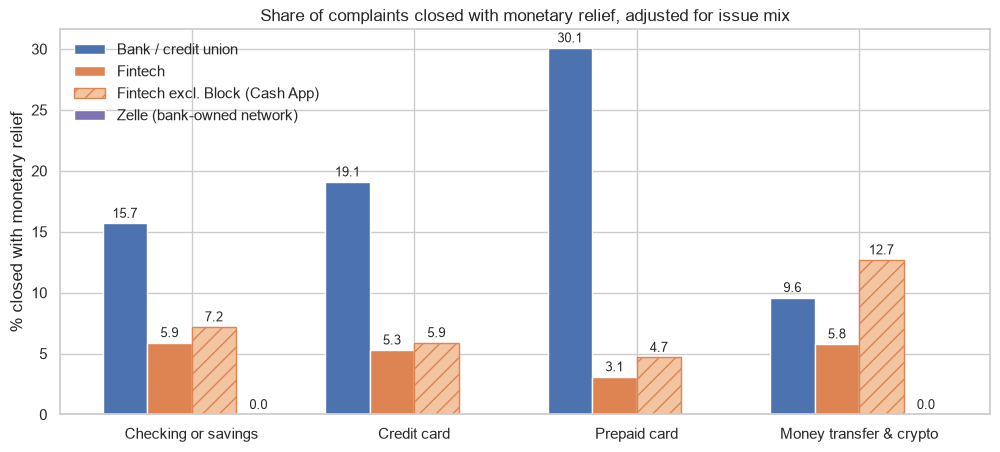

In [28]:
MIN_BAR = 200 if not USING_SAMPLE else 20
bar_specs = [
    ('Bank / credit union', adj_col(relief, 'Bank / credit union', MIN_BAR), GROUP_COLORS['Bank / credit union'], None),
    ('Fintech', adj_col(relief, 'Fintech', MIN_BAR), GROUP_COLORS['Fintech'], None),
    ('Fintech excl. Block (Cash App)', adj_col(no_block, 'Fintech', MIN_BAR), '#f2c4a0', '//'),
    ('Zelle (bank-owned network)', adj_col(relief, 'Zelle (bank-owned network)', MIN_BAR),
     GROUP_COLORS['Zelle (bank-owned network)'], None),
]
fams = [f for f in FAMILY_ORDER if any(f in s.index for _, s, _, _ in bar_specs)]
x = np.arange(len(fams))
width = 0.8 / len(bar_specs)

fig, ax = plt.subplots(figsize=(12, 5))
for i, (label, s, color, hatch) in enumerate(bar_specs):
    vals = s.reindex(fams)
    bars = ax.bar(x + (i - (len(bar_specs) - 1) / 2) * width, vals.values, width, label=label,
                  color=color, hatch=hatch, edgecolor='white' if hatch is None else '#dd8452')
    ax.bar_label(bars, labels=['' if pd.isna(v) else f'{v:.1f}' for v in vals], padding=2, fontsize=9)
ax.set_xticks(x, fams)
ax.set(title='Share of complaints closed with monetary relief, adjusted for issue mix',
       ylabel='% closed with monetary relief', xlabel='')
ax.legend(frameon=False)
save(fig, 'monetary_relief_by_group')
plt.show()

Finally, company by company. We compare monetary-relief rates for the companies with the most closed complaints in each product family, against the family average. (These are raw rates; a company with an unusual mix of problems can look better or worse for that reason alone.)

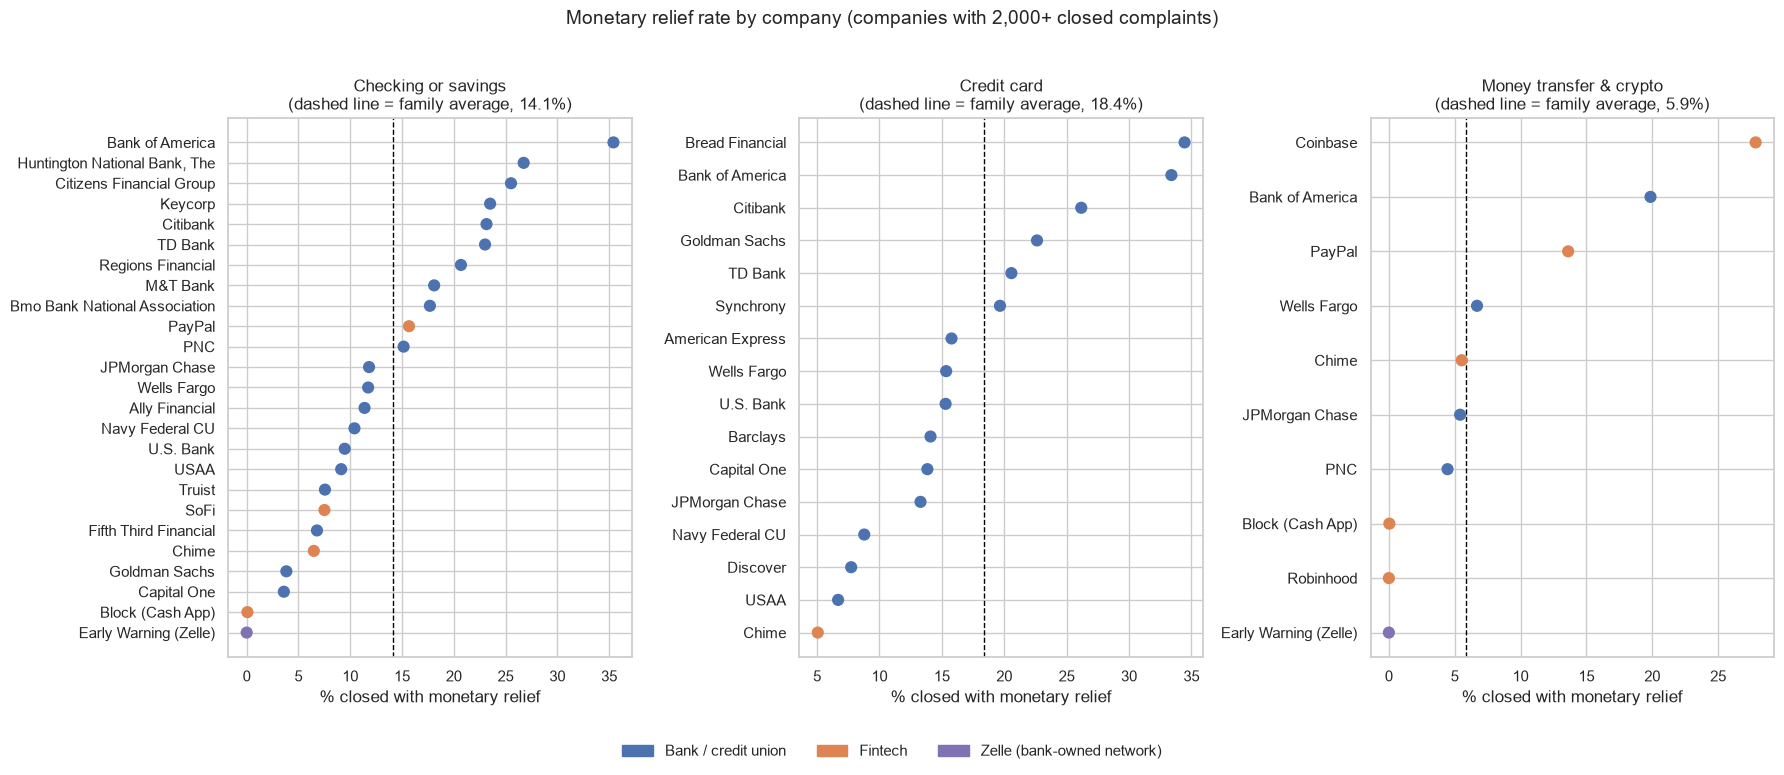

         product_family                 company_short                      group  rate     n
    Checking or savings               Bank of America        Bank / credit union  35.4 37356
    Checking or savings Huntington National Bank, The        Bank / credit union  26.7  3825
    Checking or savings      Citizens Financial Group        Bank / credit union  25.5  5458
    Checking or savings                       Keycorp        Bank / credit union  23.5  2659
    Checking or savings                      Citibank        Bank / credit union  23.2 17520
    Checking or savings                       TD Bank        Bank / credit union  23.0  7204
    Checking or savings             Regions Financial        Bank / credit union  20.7  3200
    Checking or savings                      M&T Bank        Bank / credit union  18.1  2221
    Checking or savings Bmo Bank National Association        Bank / credit union  17.7  3126
    Checking or savings                        PayPal                 

In [29]:
MIN_COMPANY = 2000 if not USING_SAMPLE else 40
comp = (closed.groupby(['product_family', 'company_short', 'group'])['monetary']
        .agg(rate='mean', n='size').reset_index())
comp = comp[comp['n'] >= MIN_COMPANY]
comp['rate'] *= 100

fams = [f for f in ['Checking or savings', 'Credit card', 'Money transfer & crypto'] if f in set(comp['product_family'])]
fig, axes = plt.subplots(1, len(fams), figsize=(6 * len(fams), 7), squeeze=False)
for ax, fam in zip(axes[0], fams):
    c = comp[comp['product_family'] == fam].sort_values('rate')
    ax.scatter(c['rate'], c['company_short'], s=60, c=c['group'].map(GROUP_COLORS), zorder=3)
    avg = closed.loc[closed['product_family'] == fam, 'monetary'].mean() * 100
    ax.axvline(avg, color='black', linestyle='--', linewidth=1)
    ax.set(title=f'{fam}\n(dashed line = family average, {avg:.1f}%)', xlabel='% closed with monetary relief', ylabel='')
fig.suptitle(f'Monetary relief rate by company (companies with {MIN_COMPANY:,}+ closed complaints)', fontsize=14, y=1.02)
fig.tight_layout()
fig.legend(handles=[Patch(color=GROUP_COLORS[g], label=g) for g in COMPARE], ncol=3, loc='upper center',
           bbox_to_anchor=(0.5, -0.01), frameon=False)
save(fig, 'relief_by_company')
plt.show()

print(comp.sort_values(['product_family', 'rate'], ascending=[True, False]).round(1).to_string(index=False))

In [30]:
timely = (closed.groupby(['product_family', 'group'])['timely'].mean() * 100).unstack().reindex(
    index=FAMILY_ORDER, columns=COMPARE).round(1)
print('% of closed complaints with a timely company response:')
timely

% of closed complaints with a timely company response:


group,Bank / credit union,Fintech,Zelle (bank-owned network)
product_family,,,
Checking or savings,99.4,97.9,100.0
Credit card,99.6,95.6,100.0
Prepaid card,99.1,97.9,100.0
Money transfer & crypto,99.4,98.7,100.0


Most complaints in every group are closed with an explanation only. Banks close far more with monetary relief: 15.6% of checking and savings complaints against 6.2% for fintechs, 19.0% vs 5.9% for credit cards, and 30.6% vs 3.5% for prepaid cards. Adjusting for the mix of issues barely changes these rates (for example 15.7% vs 5.9% in checking), so the gap isn't explained by fintechs receiving different kinds of complaints.

The checks confirm the gaps for accounts, cards and prepaid cards:

- **Without Block:** fintechs stay well below banks (for example 7.2% vs 15.7% in checking).
- **Without January 2025:** the rates hardly move.
- **Prepaid cards:** banks' average leans on a few issuers. Four of them hold 88% of banks' closed prepaid complaints, and American Express alone holds 29% with a 48.2% relief rate. Without American Express, banks' issue-adjusted rate falls from 30.1% to 24.1%, still about eight times fintechs' 3.1%.

In money transfers the raw gap is smaller (9.7% vs 5.7%) and depends on one company. Cash App closed none of its 56,459 closed money-transfer complaints with monetary relief (and 0.1% in checking). Without Block, fintechs' issue-adjusted rate rises to 12.7%, above banks' 9.6%, and this holds without January 2025 too (12.6% vs 9.5%).

Rates also vary widely within each group (raw rates for companies with enough closed complaints). In checking, Bank of America closes 35.4% of complaints with monetary relief and Capital One 3.6%. In money transfers, Coinbase closes 27.9% and PayPal 13.6%, against 0% for Cash App, Zelle and Robinhood. Zelle never records monetary relief; as a network operator it may not be the party that refunds customers, but the data can't confirm this.

Responses are timely almost everywhere (95.6–99.6%), slightly less so for fintechs. Note that the outcome is reported by the company itself, so companies may classify similar outcomes differently.

## Conclusion and recommendations

Complaints about checking, credit cards, prepaid cards and money transfers grew from 66,427 in 2020 to 265,328 in 2025. Fintechs' share was 12–17% from 2021 to 2024 and has been higher since, at 24% in 2026. The biggest single event was a burst of complaints about Zelle and then Cash App in mid-January 2025. Cash App's matches the day of a CFPB order against Block; Zelle's started two days earlier and has no clear trigger in the data. Across products, fintechs resolve complaints with money far less often than banks. This holds after adjusting for the type of problem and through every check, except in money transfers, where the fintech gap comes from Cash App alone.

**Recommendations for a fintech customer experience lead**

1. **Benchmark refund practice against banks, product by product.** For checking, credit cards and prepaid cards, banks are 2.7 to 10 times as likely to close a complaint with monetary relief, after adjusting for the type of issue. Review whether eligible disputes, such as unauthorised transactions, are being refunded.
2. **Focus on unexpected charges and transaction problems.** These are fintech customers' most distinctive complaints in checking (19.2% vs 10.5% for banks) and money transfers.
3. **Plan for sudden complaint surges.** Cash App's money-transfer complaints went from about 160 a month in 2024 to over 30,000 in January 2025, and Zelle's from about 40 a month to 16,528, mostly within a week. Regulatory news is one possible trigger, but Zelle's surge started before any matching announcement. Support capacity and a plan for clear customer communication should be ready before a surge, not built during one.
4. **Learn from fintechs that resolve complaints well.** Coinbase (27.9%) and PayPal (13.6%) close far more money-transfer complaints with monetary relief than Cash App (0%), on raw rates. So a low refund rate isn't simply a feature of being a fintech.
5. **Watch PayPal's rising volume.** Its money-transfer complaints reached 8,990 in 2026 by mid-November, already above 2025's 5,486, and October 2026 was its highest month so far.

**Caveats**

- Complaint counts aren't adjusted for how many customers each company has.
- CFPB complaints come from consumers who choose to file them, and company responses, including monetary relief, are reported by the companies themselves.
- The fintech and bank grouping is a judgement call, listed in full in section 1. SoFi and Green Dot hold bank charters but are grouped as fintechs.
- This download doesn't include consumers' written narratives, so the analysis relies on structured issue labels, which the CFPB reworded in 2023.
- Fraud shares depend on how fraud is defined. Section 6 shows them with and without a catch-all label.
- The causes of the January 2025 spikes aren't established by the data.
- 2026 is a partial year, and the outcome analysis leaves out the last 60 days of complaints, which may not be closed yet.

**Next steps:** join the consumer narratives from the CFPB's bulk file for text analysis; estimate complaint rates per customer using public user counts; and look at what the post-spike Cash App complaints (still five times 2024's level) are about.